# Yemen Food Security Early Warning
**Reproducible, leakage-aware temporal modeling notebook**

This notebook audits `YEM_JMR_data.csv`, defines a retrospective classification task for `target_ipc4`, compares models on a chronological validation window, and evaluates the selected model once on a later holdout. It intentionally does **not** claim operational early-warning validity unless feature availability dates and the target forecast horizon can be verified.

## Important data caveat
The source has monthly district rows from 2009–2026, but `target_ipc4` is missing for most rows and available only in a subset of months. The data does not include explicit publication/availability timestamps for each indicator or an unambiguous target-validity window. Consequently, the default experiment is a **time-ordered retrospective classification benchmark**, not proof that every feature was known before the target event. `predicted_prob`, target-adjacent IPC fields, and `estimated_pop_at_risk` are excluded from predictors.

## 1. Project setup

In [1]:
from pathlib import Path
import os, json, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, confusion_matrix, classification_report,
    brier_score_loss
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", platform.python_version())
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.13.5
Output directory: /mnt/data


## 2. Data loading

In [2]:
# Kaggle: attach YEM_JMR_data.csv as a dataset, or place it in /kaggle/working.
# Local execution: place the file next to this notebook or update DATA_PATH.
DATA_PATH = None
candidate_paths = []
if DATA_PATH:
    candidate_paths.append(Path(DATA_PATH))
candidate_paths += [
    Path("/kaggle/input/YEM_JMR_data.csv"),
    Path("/kaggle/working/YEM_JMR_data.csv"),
    Path.cwd() / "YEM_JMR_data.csv",
    Path("/mnt/data/YEM_JMR_data.csv"),
]
for root in [Path("/kaggle/input"), Path.cwd()]:
    if root.exists():
        try:
            candidate_paths.extend(root.rglob("YEM_JMR_data.csv"))
        except (PermissionError, OSError):
            pass
DATA_FILE = next((p for p in candidate_paths if p.is_file()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        "YEM_JMR_data.csv not found. In Kaggle, use Add Input to attach the dataset; "
        "locally, put it beside the notebook or set DATA_PATH."
    )
df = pd.read_csv(DATA_FILE, low_memory=False)
print("Loaded:", DATA_FILE)
print("Shape:", df.shape)
display(df.head())

Loaded: /mnt/data/YEM_JMR_data.csv
Shape: (71355, 52)


,adm0_name,adm0_pcode,adm1_name,adm1_pcode,adm2_name,adm2_pcode,year,month,year_month,ipc_cutoff,target_ipc4,possible_escalation_ipc4,fews_ipc,fews_ipc_ha,population,estimated_pop_at_risk,conflict_alarm,conflict_alert,drought_ndvi_alarm,drought_ndvi_alert,drought_rainfall_alarm,drought_rainfall_alert,exchange_rates_alarm,exchange_rates_alert,exchange_rates_volatility_alarm,exchange_rates_volatility_alert,food_prices_alarm,food_prices_alert,food_prices_volatility_alarm,food_prices_volatility_alert,fuel_prices_alarm,fuel_prices_alert,fuel_prices_volatility_alarm,fuel_prices_volatility_alert,heavy_rainfall_alarm,heavy_rainfall_alert,trade_food_alarm,trade_food_alert,trade_fuel_alarm,trade_fuel_alert,zone_irg,conflict_original,drought_ndvi_original,drought_rainfall_original,exchange_rates_original,exchange_rates_volatility_original,food_prices_original,food_prices_volatility_original,fuel_prices_original,fuel_prices_volatility_original,heavy_rainfall_original,predicted_prob
0,Yemen,YEM,Ibb,YE11,Al Qafr,YE1101,2026,9,2026_09,4,NaN,NaN,NaN,NaN,210740,48170.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.41,6.35,NaN,NaN,NaN,NaN,NaN,NaN,19.04,0.228577
1,Yemen,YEM,Ibb,YE11,Yarim,YE1102,2026,9,2026_09,4,NaN,NaN,NaN,NaN,366372,88114.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.4243,0.47,4.39,NaN,NaN,NaN,NaN,NaN,NaN,13.16,0.240504
2,Yemen,YEM,Ibb,YE11,Ar Radmah,YE1103,2026,9,2026_09,4,NaN,NaN,NaN,NaN,156173,36140.0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.42,2.83,NaN,NaN,NaN,NaN,NaN,NaN,8.50,0.231412
3,Yemen,YEM,Ibb,YE11,An Nadirah,YE1104,2026,9,2026_09,4,NaN,NaN,NaN,NaN,151487,34856.0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.9156,0.53,4.22,NaN,NaN,NaN,NaN,NaN,NaN,12.67,0.230092
4,Yemen,YEM,Ibb,YE11,Ash Sha'ir,YE1105,2026,9,2026_09,4,NaN,NaN,NaN,NaN,83006,24052.0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.1160,0.64,5.50,NaN,NaN,NaN,NaN,NaN,NaN,16.50,0.289760


## 3. Data quality audit

In [3]:
required_columns = {"target_ipc4", "year", "month", "year_month", "adm2_pcode"}
missing_required = sorted(required_columns - set(df.columns))
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "n_unique_including_na": df.nunique(dropna=False),
}).sort_values(["missing_pct", "n_unique_including_na"], ascending=[False, True])
display(audit)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate district-month keys:", int(df.duplicated(["adm2_pcode", "year_month"]).sum()))
print("Date range:", df["year"].min(), "to", df["year"].max())
print("Target values (including missing):")
display(df["target_ipc4"].value_counts(dropna=False).rename_axis("target_ipc4").to_frame("rows"))
print("Target prevalence by year:")
display(df.groupby("year")["target_ipc4"].agg(["count", "mean"]).rename(columns={"count":"labeled_rows","mean":"positive_rate"}))

,dtype,missing_count,missing_pct,n_unique_including_na
possible_escalation_ipc4,float64,60982,85.46,3
target_ipc4,float64,60647,84.99,3
fews_ipc,float64,60647,84.99,4
fews_ipc_ha,float64,60647,84.99,5
conflict_original,float64,24120,33.80,6036
food_prices_original,float64,2010,2.82,22641
food_prices_volatility_original,float64,2010,2.82,22641
exchange_rates_original,float64,2010,2.82,65150
exchange_rates_volatility_original,float64,2010,2.82,65150
fuel_prices_original,float64,2010,2.82,69115


Exact duplicate rows: 0
Duplicate district-month keys: 0
Date range: 2009 to 2026
Target values (including missing):


,rows
target_ipc4,
NaN,60647
0.0,6183
1.0,4525


Target prevalence by year:


,labeled_rows,positive_rate
year,,
2009,0,NaN
2010,0,NaN
2011,0,NaN
2012,0,NaN
2013,0,NaN
2014,335,0.000000
2015,1340,0.251493
2016,1001,0.398601
2017,666,0.504505


## 4. Target definition and temporal coverage

Labeled rows: 10,708 / 71,355 (15.0%)
Distinct labeled months: 32


,year_month,count,mean
12,2018_10,335,0.450746
13,2019_02,335,0.450746
14,2019_06,335,0.450746
15,2019_10,335,0.492537
16,2020_02,335,0.492537
17,2020_06,335,0.492537
18,2020_10,335,0.492537
19,2021_02,335,0.492537
20,2021_06,335,0.492537
21,2021_10,335,0.492537


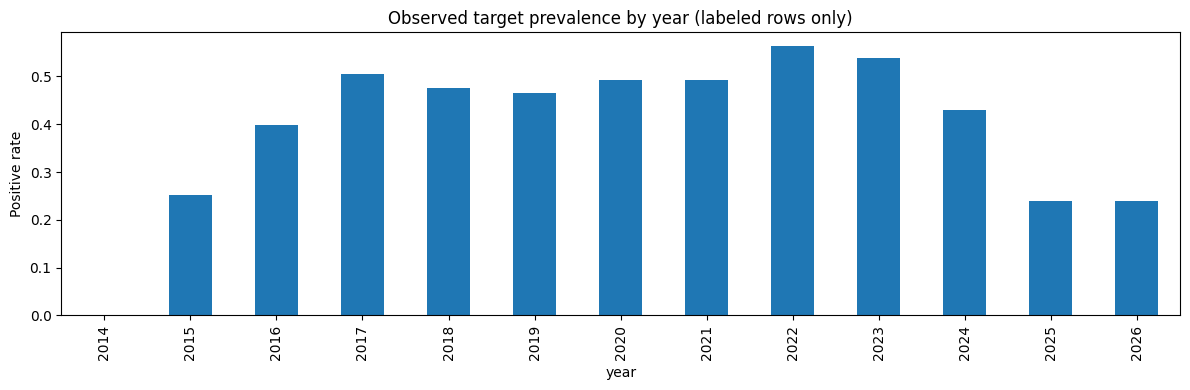

In [4]:
# The source column is named target_ipc4 and observed values are 0/1.
# This notebook does not infer an IPC threshold or horizon beyond the source definition.
target_values = set(df["target_ipc4"].dropna().unique())
if not target_values.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(f"target_ipc4 is not binary 0/1 as expected: {sorted(target_values)}")
df["date"] = pd.to_datetime(df["year_month"].astype(str).str.replace("_", "-", regex=False) + "-01", errors="coerce")
labeled = df.loc[df["target_ipc4"].notna() & df["date"].notna()].copy()
labeled["target_ipc4"] = labeled["target_ipc4"].astype(int)
target_month_summary = labeled.groupby("year_month")["target_ipc4"].agg(["count","mean"]).reset_index()
print(f"Labeled rows: {len(labeled):,} / {len(df):,} ({len(labeled)/len(df):.1%})")
print("Distinct labeled months:", labeled["year_month"].nunique())
display(target_month_summary.tail(20))
fig, ax = plt.subplots(figsize=(12, 4))
yearly = labeled.groupby("year")["target_ipc4"].mean()
yearly.plot(kind="bar", ax=ax)
ax.set_title("Observed target prevalence by year (labeled rows only)")
ax.set_ylabel("Positive rate")
plt.tight_layout()
plt.show()

## 5. Leakage prevention and feature audit

In [5]:
# Exclude target, target-adjacent IPC outcomes, the precomputed model probability,
# and estimated population at risk (plausibly outcome-derived). Also exclude free-text
# geography names only when their coded equivalent is present? Here names/codes are
# retained as static geographic context; one-hot encoding is fitted on training only.
EXCLUDE = {
    "target_ipc4", "possible_escalation_ipc4", "fews_ipc", "fews_ipc_ha",
    "predicted_prob", "ipc_cutoff", "estimated_pop_at_risk",
    "year_month", "date", "adm0_name", "adm0_pcode"
}
candidate_features = [c for c in df.columns if c not in EXCLUDE]
# The six named original price/exchange columns are exact duplicates in this dataset
# for each of the three pairs shown below. Keep one column per pair.
duplicate_pairs = [
    ("exchange_rates_original", "exchange_rates_volatility_original"),
    ("food_prices_original", "food_prices_volatility_original"),
    ("fuel_prices_original", "fuel_prices_volatility_original"),
]
duplicate_pair_audit = []
for keep_col, drop_col in duplicate_pairs:
    exact = (keep_col in df.columns and drop_col in df.columns and
             df[keep_col].equals(df[drop_col]))
    duplicate_pair_audit.append({"kept": keep_col, "dropped_if_exact": drop_col, "exactly_equal_including_NA": bool(exact)})
    if exact and drop_col in candidate_features:
        candidate_features.remove(drop_col)
display(pd.DataFrame(duplicate_pair_audit))
print("Candidate features:", candidate_features)
print("CAUTION: indicator publication/availability timestamps are absent. Alarm/alert features may be contemporaneous; therefore results are not proof of real-time early-warning performance.")

,kept,dropped_if_exact,exactly_equal_including_NA
0,exchange_rates_original,exchange_rates_volatility_original,True
1,food_prices_original,food_prices_volatility_original,True
2,fuel_prices_original,fuel_prices_volatility_original,True


Candidate features: ['adm1_name', 'adm1_pcode', 'adm2_name', 'adm2_pcode', 'year', 'month', 'population', 'conflict_alarm', 'conflict_alert', 'drought_ndvi_alarm', 'drought_ndvi_alert', 'drought_rainfall_alarm', 'drought_rainfall_alert', 'exchange_rates_alarm', 'exchange_rates_alert', 'exchange_rates_volatility_alarm', 'exchange_rates_volatility_alert', 'food_prices_alarm', 'food_prices_alert', 'food_prices_volatility_alarm', 'food_prices_volatility_alert', 'fuel_prices_alarm', 'fuel_prices_alert', 'fuel_prices_volatility_alarm', 'fuel_prices_volatility_alert', 'heavy_rainfall_alarm', 'heavy_rainfall_alert', 'trade_food_alarm', 'trade_food_alert', 'trade_fuel_alarm', 'trade_fuel_alert', 'zone_irg', 'conflict_original', 'drought_ndvi_original', 'drought_rainfall_original', 'exchange_rates_original', 'food_prices_original', 'fuel_prices_original', 'heavy_rainfall_original']
CAUTION: indicator publication/availability timestamps are absent. Alarm/alert features may be contemporaneous; the

## 6. Exploratory checks

In [6]:
# Check whether rows are one per district-month and inspect missingness by year.
display(df.groupby("year").size().rename("rows").to_frame())
if "adm2_pcode" in df:
    display(df.groupby("year")["adm2_pcode"].nunique().rename("unique_districts").to_frame())
original_cols = [c for c in df.columns if c.endswith("_original")]
if original_cols:
    display(df[original_cols].describe().T)

,rows
year,
2009,4020
2010,4020
2011,4020
2012,4020
2013,4020
2014,4020
2015,4020
2016,4020
2017,4020


,unique_districts
year,
2009,335
2010,335
2011,335
2012,335
2013,335
2014,335
2015,335
2016,335
2017,335


,count,mean,std,min,25%,50%,75%,max
conflict_original,47235.0,1.273518,2.051503,0.00,0.0000,0.3960,1.7492,24.1204
drought_ndvi_original,71355.0,0.194137,0.095511,0.06,0.1300,0.1600,0.2300,0.7000
drought_rainfall_original,71355.0,6.087213,9.626429,0.00,1.3100,2.4200,6.3200,137.1400
exchange_rates_original,69345.0,530.843941,391.857502,235.39,284.8520,398.6299,584.8754,2791.8900
exchange_rates_volatility_original,69345.0,530.843941,391.857502,235.39,284.8520,398.6299,584.8754,2791.8900
food_prices_original,69345.0,1.516386,1.111032,0.42,0.8000,0.9980,1.8342,8.8200
food_prices_volatility_original,69345.0,1.516386,1.111032,0.42,0.8000,0.9980,1.8342,8.8200
fuel_prices_original,69345.0,1729.305659,788.561564,625.99,1163.7806,1429.7104,2259.8524,11281.7200
fuel_prices_volatility_original,69345.0,1729.305659,788.561564,625.99,1163.7806,1429.7104,2259.8524,11281.7200
heavy_rainfall_original,71355.0,18.261620,28.879250,0.00,3.9400,7.2500,18.9500,411.4300


## 7. Temporal split (train / validation / test)

In [7]:
# Split by whole labeled months, never by random rows. First 60% of labeled months
# train, next 20% validate, final 20% test. Test is not used for model selection.
months = np.array(sorted(labeled["date"].dropna().unique()))
if len(months) < 10:
    raise ValueError(f"Too few distinct labeled months for a meaningful temporal split: {len(months)}")
train_end = months[max(0, int(np.floor(len(months)*0.60))-1)]
val_end = months[max(1, int(np.floor(len(months)*0.80))-1)]
train_df = labeled.loc[labeled["date"] <= train_end].copy()
val_df = labeled.loc[(labeled["date"] > train_end) & (labeled["date"] <= val_end)].copy()
test_df = labeled.loc[labeled["date"] > val_end].copy()
if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("Temporal split produced an empty partition; inspect labeled month coverage.")
print("Train through:", pd.Timestamp(train_end).date(), "| rows:", len(train_df))
print("Validation:", (train_df["date"].max()+pd.Timedelta(days=1)).date(), "through", pd.Timestamp(val_end).date(), "| rows:", len(val_df))
print("Test after:", pd.Timestamp(val_end).date(), "| rows:", len(test_df))
for name, part in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, "date range", part["date"].min(), "to", part["date"].max(),
          "| positive rate", round(part["target_ipc4"].mean(), 4))
assert train_df["date"].max() < val_df["date"].min() < test_df["date"].min()

Train through: 2020-10-01 | rows: 6353
Validation: 2020-10-02 through 2022-10-01 | rows: 2010
Test after: 2022-10-01 | rows: 2345
train date range 2014-10-01 00:00:00 to 2020-10-01 00:00:00 | positive rate 0.3951
validation date range 2021-02-01 00:00:00 to 2022-10-01 00:00:00 | positive rate 0.5284
test date range 2023-02-01 00:00:00 to 2026-02-01 00:00:00 | positive rate 0.4064


## 8. Model training and validation comparison

In [8]:
# All preprocessing is inside each Pipeline, fitted on training data only.
features = [c for c in candidate_features if c in train_df.columns]
X_train, y_train = train_df[features], train_df["target_ipc4"]
X_val, y_val = val_df[features], val_df["target_ipc4"]
X_test, y_test = test_df[features], test_df["target_ipc4"]
cat_cols = [c for c in features if X_train[c].dtype == "object"]
num_cols = [c for c in features if c not in cat_cols]

def make_preprocessor(scale_numeric=False, dense=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    categorical_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)),
    ]
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), num_cols),
        ("categorical", Pipeline(categorical_steps), cat_cols),
    ])

model_specs = {
    "Logistic Regression": (LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE), True, False),
    "Random Forest": (RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1), False, False),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), False, False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, l2_regularization=1.0, random_state=RANDOM_STATE), False, True),
}

def metrics_at_threshold(y, prob, threshold=0.5):
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y, prob) if pd.Series(y).nunique() == 2 else np.nan,
        "PR_AUC": average_precision_score(y, prob) if pd.Series(y).nunique() == 2 else np.nan,
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y, pred),
        "Brier": brier_score_loss(y, prob),
    }

fitted_models, validation_probabilities, rows = {}, {}, []
for name, (estimator, scale, dense) in model_specs.items():
    prep = make_preprocessor(scale_numeric=scale, dense=dense)
    pipe = Pipeline([("preprocess", prep), ("model", estimator)])
    try:
        pipe.fit(X_train, y_train)
        prob = pipe.predict_proba(X_val)[:, 1]
        fitted_models[name] = pipe
        validation_probabilities[name] = prob
        rows.append({"Model": name, **metrics_at_threshold(y_val, prob, 0.5), "status": "ok"})
        print("Completed:", name)
    except Exception as exc:
        rows.append({"Model": name, "status": f"failed: {type(exc).__name__}: {exc}"})
        print("Model skipped due to error:", name, repr(exc))

validation_results = pd.DataFrame(rows)
display(validation_results.sort_values("ROC_AUC", ascending=False, na_position="last"))
validation_results.to_csv(OUTPUT_DIR / "model_comparison_validation.csv", index=False)
if not fitted_models:
    raise RuntimeError("All candidate models failed; inspect error output.")
# Select on validation ROC-AUC; PR-AUC and operational metrics remain visible for context.
selection_table = validation_results.loc[validation_results["status"] == "ok"].sort_values(
    ["ROC_AUC", "PR_AUC"], ascending=False
)
selected_name = selection_table.iloc[0]["Model"]
selected_model = fitted_models[selected_name]
selected_val_prob = validation_probabilities[selected_name]
print("Selected using validation only:", selected_name)

Completed: Logistic Regression


Completed: Random Forest


Completed: Extra Trees


Completed: HistGradientBoosting


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1,Balanced_Accuracy,Brier,status
3,HistGradientBoosting,0.976546,0.984809,1.000000,0.919021,0.957802,0.959510,0.038782,ok
2,Extra Trees,0.973844,0.984128,0.998962,0.905838,0.950123,0.952392,0.073719,ok
1,Random Forest,0.972976,0.983360,0.982915,0.920904,0.950899,0.951486,0.086444,ok
0,Logistic Regression,0.895281,0.919519,0.796999,0.850282,0.822779,0.803833,0.141468,ok


Selected using validation only: HistGradientBoosting


## 9. Threshold selection on validation only

In [9]:
# Threshold is chosen on validation by maximizing F1. This is a generic statistical
# criterion, not a policy recommendation; humanitarian operations may prefer a recall
# target, a precision floor, or cost-based utility defined with domain stakeholders.
threshold_grid = np.linspace(0.05, 0.95, 181)
threshold_rows = []
for threshold in threshold_grid:
    m = metrics_at_threshold(y_val, selected_val_prob, float(threshold))
    threshold_rows.append({"threshold": float(threshold), **m})
threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_table.loc[threshold_table["F1"].idxmax(), "threshold"])
display(threshold_table.sort_values("F1", ascending=False).head(10))
print("Validation-selected F1 threshold:", best_threshold)
threshold_table.to_csv(OUTPUT_DIR / "threshold_selection_validation.csv", index=False)

,threshold,ROC_AUC,PR_AUC,Precision,Recall,F1,Balanced_Accuracy,Brier
32,0.210,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
33,0.215,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
34,0.220,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
35,0.225,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
28,0.190,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
29,0.195,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
38,0.240,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
37,0.235,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
40,0.250,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782
41,0.255,0.976546,0.984809,1.0,0.932203,0.964912,0.966102,0.038782


Validation-selected F1 threshold: 0.19


## 10. Final test evaluation (one-time holdout)

In [10]:
# Do not tune on test. Model and threshold were chosen from validation only.
test_prob = selected_model.predict_proba(X_test)[:, 1]
test_metrics = metrics_at_threshold(y_test, test_prob, best_threshold)
test_metrics.update({
    "Model": selected_name,
    "threshold_from_validation": best_threshold,
    "test_rows": int(len(test_df)),
    "test_start": str(test_df["date"].min().date()),
    "test_end": str(test_df["date"].max().date()),
    "test_positive_rate": float(y_test.mean()),
})
display(pd.DataFrame([test_metrics]))
test_predictions = test_df[["adm2_pcode","adm2_name","year_month","target_ipc4"]].copy()
test_predictions["predicted_probability"] = test_prob
test_predictions["predicted_label"] = (test_prob >= best_threshold).astype(int)
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)
print("Confusion matrix at validation-selected threshold:")
print(confusion_matrix(y_test, test_predictions["predicted_label"]))
print(classification_report(y_test, test_predictions["predicted_label"], zero_division=0))

,ROC_AUC,PR_AUC,Precision,Recall,F1,Balanced_Accuracy,Brier,Model,threshold_from_validation,test_rows,test_start,test_end,test_positive_rate
0,0.831653,0.7746,0.681739,0.822665,0.745602,0.779867,0.216328,HistGradientBoosting,0.19,2345,2023-02-01,2026-02-01,0.406397


Confusion matrix at validation-selected threshold:
[[1026  366]
 [ 169  784]]
              precision    recall  f1-score   support

           0       0.86      0.74      0.79      1392
           1       0.68      0.82      0.75       953

    accuracy                           0.77      2345
   macro avg       0.77      0.78      0.77      2345
weighted avg       0.79      0.77      0.77      2345



## 11. Error analysis

,year_month,rows,positive_rate,predicted_positive_rate,accuracy,mean_probability
0,2023_02,335.0,0.474627,0.501493,0.782090,0.481263
1,2023_06,335.0,0.602985,0.492537,0.889552,0.474681
2,2024_02,335.0,0.214925,0.486567,0.597015,0.473558
3,2024_06,335.0,0.602985,0.486567,0.883582,0.471588
4,2024_10,335.0,0.471642,0.486567,0.752239,0.470959
5,2025_10,335.0,0.238806,0.480597,0.758209,0.473974
6,2026_02,335.0,0.238806,0.498507,0.740299,0.471472


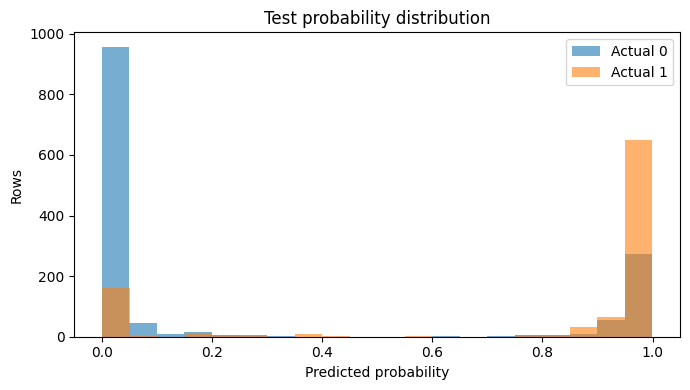

In [11]:
test_predictions["correct"] = test_predictions["predicted_label"] == test_predictions["target_ipc4"]
display(test_predictions.groupby("year_month").apply(
    lambda g: pd.Series({
        "rows": len(g),
        "positive_rate": g["target_ipc4"].mean(),
        "predicted_positive_rate": g["predicted_label"].mean(),
        "accuracy": g["correct"].mean(),
        "mean_probability": g["predicted_probability"].mean(),
    }), include_groups=False
).reset_index())
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(test_predictions.loc[test_predictions["target_ipc4"] == 0, "predicted_probability"], bins=20, alpha=0.6, label="Actual 0")
ax.hist(test_predictions.loc[test_predictions["target_ipc4"] == 1, "predicted_probability"], bins=20, alpha=0.6, label="Actual 1")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Rows"); ax.set_title("Test probability distribution")
ax.legend(); plt.tight_layout(); plt.show()

## 12. Feature importance (validation only)

In [12]:
# Permutation importance is measured on validation and is descriptive, not causal.
# Limit repeats for runtime; correlated features can split importance across variables.
try:
    perm = permutation_importance(
        selected_model, X_val, y_val, scoring="roc_auc",
        n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1
    )
    importance = pd.DataFrame({
        "feature": features,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    }).sort_values("importance_mean", ascending=False)
    display(importance.head(20))
    importance.to_csv(OUTPUT_DIR / "feature_importance_validation.csv", index=False)
except Exception as exc:
    print("Permutation importance could not be computed:", repr(exc))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,feature,importance_mean,importance_std
0,adm1_name,0.443220,0.013463
16,exchange_rates_volatility_alert,0.002909,0.000177
31,zone_irg,0.001203,0.000666
36,food_prices_original,0.001078,0.000840
6,population,0.001026,0.000530
33,drought_ndvi_original,0.000724,0.000374
18,food_prices_alert,0.000584,0.000013
32,conflict_original,0.000574,0.000257
5,month,0.000481,0.000282
38,heavy_rainfall_original,0.000420,0.000201


## 13. Save artifacts and run metadata

In [13]:
metadata = {
    "project": "Yemen Food Security Early Warning",
    "data_file": str(DATA_FILE),
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "labeled_rows": int(len(labeled)),
    "labeled_months": int(labeled["year_month"].nunique()),
    "train_end": str(pd.Timestamp(train_end).date()),
    "validation_end": str(pd.Timestamp(val_end).date()),
    "selected_model": selected_name,
    "validation_selected_threshold": best_threshold,
    "test_metrics": {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in test_metrics.items()},
    "excluded_columns": sorted(EXCLUDE),
    "exact_duplicate_pairs": duplicate_pair_audit,
    "random_state": RANDOM_STATE,
    "interpretation": "Retrospective temporal benchmark; not validated as operational early warning because feature availability timestamps and target horizon are not supplied.",
}
with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)
print("Artifacts saved to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.glob("*.csv")) + ["run_metadata.json"])

Artifacts saved to: /mnt/data
['YEM_JMR_data.csv', 'feature_importance_validation.csv', 'final_test_metrics.csv', 'model_comparison_validation.csv', 'test_predictions.csv', 'threshold_selection_validation.csv', 'run_metadata.json']


## 14. Limitations and conclusion

- `target_ipc4` is treated as the source-provided binary label; this notebook does not infer its policy definition or forecast horizon.
- Most rows have no label, and labels occur only in a subset of months. Evaluation therefore applies only to labeled rows and observed labeled periods.
- The data lacks explicit feature publication timestamps and target event/validity dates. Alarm/alert and original indicators may be contemporaneous with the target. High scores must not be interpreted as evidence of lead time.
- The original/volatility columns for exchange rates, food prices, and fuel prices are exact duplicates in this file; only one from each exact pair is retained.
- Geographic IDs can encode stable district-level patterns. For a stronger generalization test, add a separate district-held-out evaluation in addition to chronological testing.
- Before operational deployment: document source timestamps, define an explicit forecast horizon (for example, predict a future IPC4 state at t+h), create features using only data published by time t, validate rolling-origin splits, calibrate probabilities, and agree on a response threshold with domain experts.